In [ ]:
import tensorflow.keras
from google.colab import drive
drive.mount('/content/drive',force_remount = True)

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = '/content/drive/My Drive/Colab Notebooks/btc.csv'
data = pd.read_csv(file_path)



# Display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

data.head()

,Date,Open Price (USD),High Price (USD),Low Price (USD),Closing Price (USD),Adjusted Closing Price (USD),Trading Volume
0,2023-09-06,25772.601563,25845.994141,25708.595703,25721.945313,25721.945313,10252755968
1,2023-09-05,25814.957031,25858.375000,25589.988281,25779.982422,25779.982422,11094740040
2,2023-09-04,25968.169922,26081.525391,25657.025391,25812.416016,25812.416016,10680635106
3,2023-09-03,25869.472656,26087.148438,25817.031250,25969.566406,25969.566406,8962524523
4,2023-09-02,25800.910156,25970.285156,25753.093750,25868.798828,25868.798828,10100387473


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3171 entries, 0 to 3170
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Date                          3171 non-null   object 
 1   Open Price (USD)              3171 non-null   float64
 2   High Price (USD)              3171 non-null   float64
 3   Low Price (USD)               3171 non-null   float64
 4   Closing Price (USD)           3171 non-null   float64
 5   Adjusted Closing Price (USD)  3171 non-null   float64
 6   Trading Volume                3171 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 173.5+ KB


In [ ]:
data = data.drop(columns=['Date'])
data

,Open Price (USD),High Price (USD),Low Price (USD),Closing Price (USD),Adjusted Closing Price (USD),Trading Volume
0,25772.601563,25845.994141,25708.595703,25721.945313,25721.945313,10252755968
1,25814.957031,25858.375000,25589.988281,25779.982422,25779.982422,11094740040
2,25968.169922,26081.525391,25657.025391,25812.416016,25812.416016,10680635106
3,25869.472656,26087.148438,25817.031250,25969.566406,25969.566406,8962524523
4,25800.910156,25970.285156,25753.093750,25868.798828,25868.798828,10100387473
5,25934.021484,26125.869141,25362.609375,25800.724609,25800.724609,17202862221
6,27301.929688,27456.078125,25752.929688,25931.472656,25931.472656,20181001451
7,27726.083984,27760.160156,27069.207031,27297.265625,27297.265625,16343655235
8,26102.486328,28089.337891,25912.628906,27727.392578,27727.392578,29368391712
9,26089.615234,26198.578125,25880.599609,26106.150391,26106.150391,11002805166


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score

df = pd.DataFrame(data)
X = df[['Open Price (USD)','High Price (USD)','Low Price (USD)','Closing Price (USD)','Adjusted Closing Price (USD)']]
y = df['Trading Volume']

# Membagi dataset menjadi data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#standarisasi target x
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

# Standarisasi target (y)
scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_test = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()


Mean Absolute Error (MAE): 0.4532119738067732
Mean Squared Error (MSE): 0.34734649461929323
Root Mean Squared Error (RMSE): 0.589361090180963
R-squared (R²): 0.5959857931136947


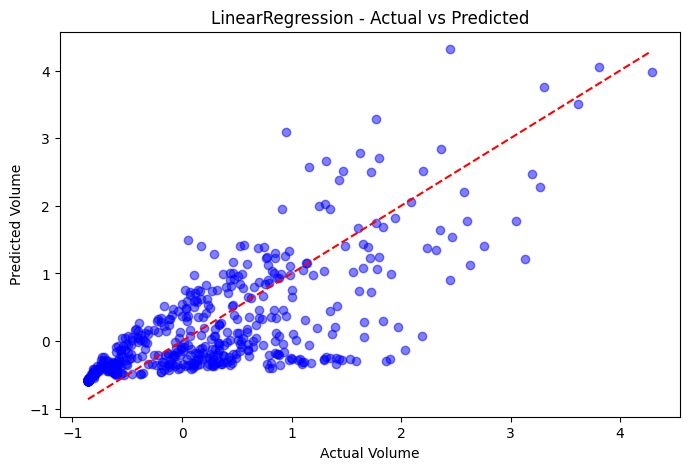

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

# Prediksi
y_predl = model.predict(X_test)

# Evaluasi model
mae = mean_absolute_error(y_test, y_predl)
mse = mean_squared_error(y_test, y_predl)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predl)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"R-squared (R²): {r2}")

# 8️⃣ Visualisasi Prediksi vs Aktual
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_predl, alpha=0.5, color="blue")
plt.xlabel("Actual Volume")
plt.ylabel("Predicted Volume")
plt.title("LinearRegression - Actual vs Predicted")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="red", linestyle="--")  # Garis referensi
plt.show()

Random Forest - Mean Absolute Error (MAE): 0.32075862358697793
Random Forest - Mean Squared Error (MSE): 0.28035925588819544
Random Forest - Root Mean Squared Error (RMSE): 0.5294896183006759
Random Forest - R-squared (R²): 0.6739016395284143


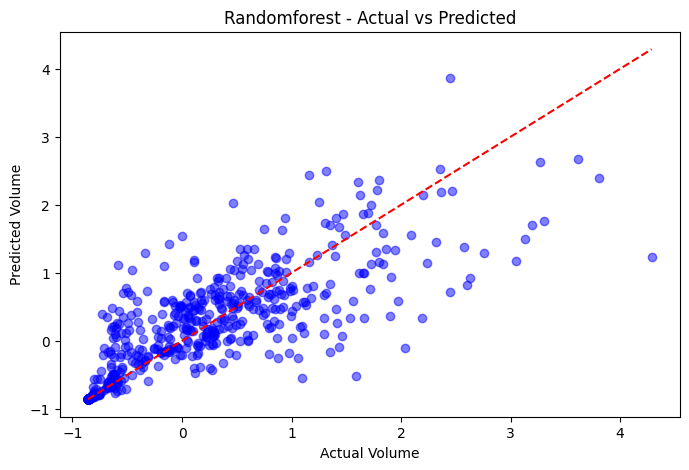

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Membuat model Random Forest
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

# Prediksi
y_pred_rf = model_rf.predict(X_test)

# Evaluasi model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest - Mean Absolute Error (MAE): {mae_rf}")
print(f"Random Forest - Mean Squared Error (MSE): {mse_rf}")
print(f"Random Forest - Root Mean Squared Error (RMSE): {rmse_rf}")
print(f"Random Forest - R-squared (R²): {r2_rf}")

# 8️⃣ Visualisasi Prediksi vs Aktual
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color="blue")
plt.xlabel("Actual Volume")
plt.ylabel("Predicted Volume")
plt.title("Randomforest - Actual vs Predicted")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="red", linestyle="--")  # Garis referensi
plt.show()

Mean Squared Error (MSE): 0.3198461029892648
Root Mean Squared Error (RMSE): 0.5655493815656285
Mean Absolute Error (MAE): 0.3245777466880605
R-squared (R2): 0.6279727257172506


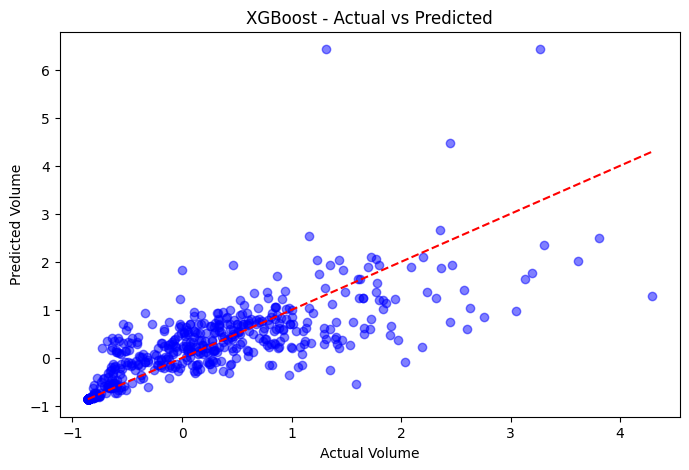

In [ ]:
import matplotlib.pyplot as plt
import xgboost as xgb
# 6️⃣ Latih Model XGBoost
model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train)

# 7️⃣ Evaluasi Model
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R-squared (R2): {r2}")

# 8️⃣ Visualisasi Prediksi vs Aktual
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.5, color="blue")
plt.xlabel("Actual Volume")
plt.ylabel("Predicted Volume")
plt.title("XGBoost - Actual vs Predicted")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="red", linestyle="--")  # Garis referensi
plt.show()

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Tuned Random Forest - Mean Absolute Error (MAE): 0.3192257528549221
Tuned Random Forest - Mean Squared Error (MSE): 0.279075568079981
Tuned Random Forest - Root Mean Squared Error (RMSE): 0.5282760339822175
Tuned Random Forest - R-squared (R²): 0.6753947540977546
Best Hyperparameters: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 30}


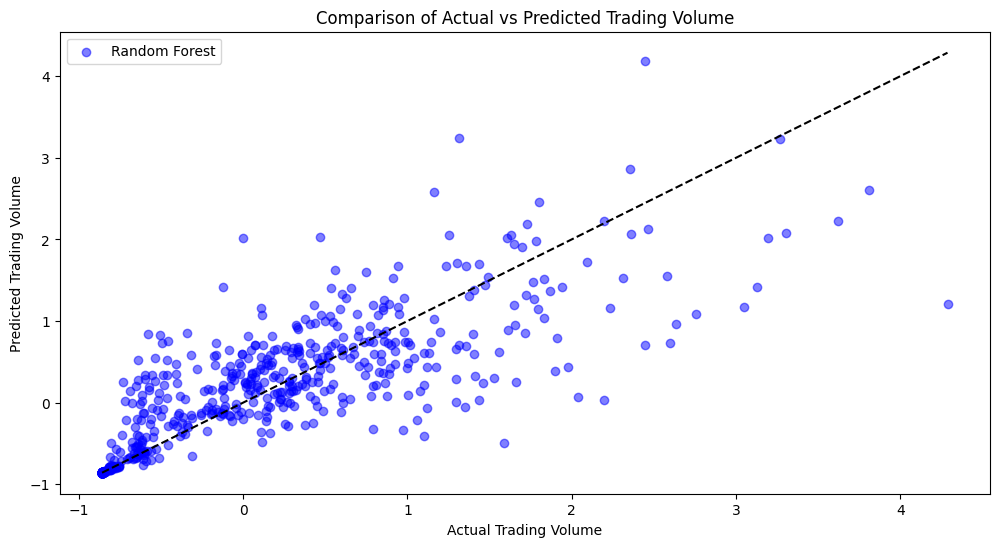

In [ ]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

rf_model = RandomForestRegressor(random_state=42)
rf_grid_search = RandomizedSearchCV(rf_model, param_grid, n_iter=10, cv=3, scoring='r2', n_jobs=-1, verbose=2)
rf_grid_search.fit(X_train, y_train)

# Menggunakan model terbaik dari tuning
best_rf_model = rf_grid_search.best_estimator_
y_rf_pred = best_rf_model.predict(X_test)

# Evaluasi model
mae = mean_absolute_error(y_test, y_rf_pred)
mse = mean_squared_error(y_test, y_rf_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_rf_pred)

print(f"Tuned Random Forest - Mean Absolute Error (MAE): {mae}")
print(f"Tuned Random Forest - Mean Squared Error (MSE): {mse}")
print(f"Tuned Random Forest - Root Mean Squared Error (RMSE): {rmse}")
print(f"Tuned Random Forest - R-squared (R²): {r2}")

print("Best Hyperparameters:", rf_grid_search.best_params_)
plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_rf_pred, color='blue', alpha=0.5, label='Random Forest')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='black', linestyle='dashed')
plt.xlabel("Actual Trading Volume")
plt.ylabel("Predicted Trading Volume")
plt.title("Comparison of Actual vs Predicted Trading Volume")
plt.legend()
plt.show()

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Tuned XGBoost - Mean Absolute Error (MAE): 0.3270498163760223
Tuned XGBoost - Mean Squared Error (MSE): 0.27259033892440576
Tuned XGBoost - Root Mean Squared Error (RMSE): 0.5221018472715891
Tuned XGBoost - R-squared (R²): 0.6829380135068857
Best Hyperparameters: {'subsample': 1.0, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.1, 'gamma': 0.3, 'colsample_bytree': 0.6}


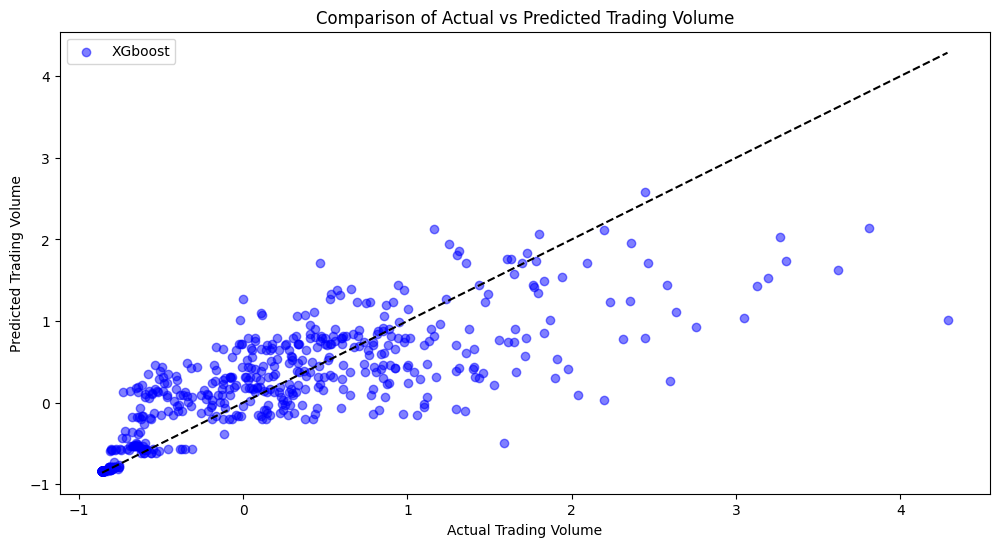

In [ ]:
import xgboost as xgb

param_grid_xgb = {
    'n_estimators': [100, 300, 500, 800, 1000],  # Lebih banyak opsi
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],  # Coba variasi learning rate
    'max_depth': [3, 5, 7, 10, 15],  # Lebih banyak opsi kedalaman
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],  # Sampling data untuk mencegah overfitting
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],  # Sampling fitur
    'gamma': [0, 0.1, 0.2, 0.3, 0.5],  # Regularisasi untuk split
    'reg_alpha': [0, 0.01, 0.1, 1, 10],  # L1 regularization (Lasso)
    'reg_lambda': [0, 0.01, 0.1, 1, 10]  # L2 regularization (Ridge)
}

xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)

# Menggunakan model terbaik dari tuning
xg_grid = RandomizedSearchCV(xgb_model, param_grid_xgb, n_iter=20, cv=3, scoring='r2', n_jobs=-1, verbose=2)
xg_grid.fit(X_train, y_train)

#cari model terbaik dari xgb
best_xgb_model = xg_grid.best_estimator_
y_pred_xgb = best_xgb_model.predict(X_test)

# Evaluasi model
mae = mean_absolute_error(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_xgb)

print(f"Tuned XGBoost - Mean Absolute Error (MAE): {mae}")
print(f"Tuned XGBoost - Mean Squared Error (MSE): {mse}")
print(f"Tuned XGBoost - Root Mean Squared Error (RMSE): {rmse}")
print(f"Tuned XGBoost - R-squared (R²): {r2}")

print("Best Hyperparameters:", xg_grid.best_params_)

plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_pred_xgb, color='blue', alpha=0.5, label='XGboost')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='black', linestyle='dashed')
plt.xlabel("Actual Trading Volume")
plt.ylabel("Predicted Trading Volume")
plt.title("Comparison of Actual vs Predicted Trading Volume")
plt.legend()
plt.show()

In [ ]:
# Fungsi untuk prediksi data baru
def predict_new_data(model, new_data):
    new_data = pd.DataFrame([new_data], columns=X.columns)  # Pastikan ada feature names
    new_data = scaler_X.transform(new_data)  # Standarisasi fitur
    prediction = model.predict(new_data)
    return prediction[0]

# Contoh penggunaan prediksi data baru
new_data = [90000, 92000, 80000, 89000, 93500]  # Open, High, Low, Close, Adj Close
predicted_rf_volume = predict_new_data(best_rf_model, new_data)
predicted_xgb_volume = predict_new_data(best_xgb_model, new_data)

# Inverse transform untuk mengembalikan ke skala asli
predicted_rf_volume_original = scaler_y.inverse_transform([[predicted_rf_volume]])[0, 0]
predicted_xgb_volume_original = scaler_y.inverse_transform([[predicted_xgb_volume]])[0, 0]

print(f"Predicted Trading Volume (Random Forest, Original Scale): {predicted_rf_volume_original}")
print(f"Predicted Trading Volume (XGBoost, Original Scale): {predicted_xgb_volume_original}")


Predicted Trading Volume (Random Forest, Original Scale): 39114282574.71517
Predicted Trading Volume (XGBoost, Original Scale): 40850164267.62795
